In [2]:
import requests
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter


<Response [200]>


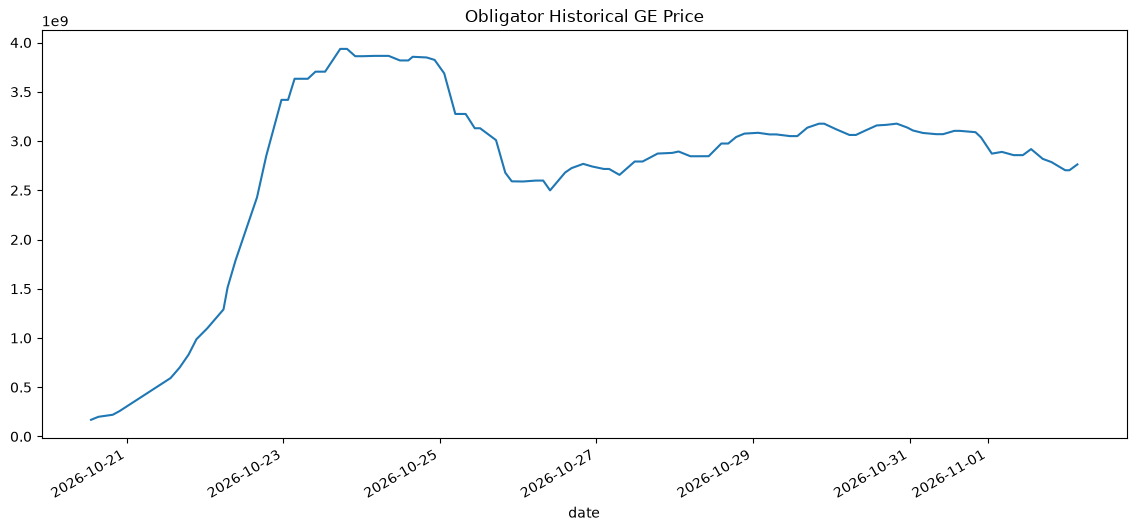

In [6]:
URL = "https://api.weirdgloop.org/exchange/history/osrs/all"
PARAMS = {"id": 34717}
HEADERS = {"User-Agent": "WEBDATASCIENCE OSRS Research Project/1.0, simon.spillane@colorado.edu"}
response = requests.get(URL, params=PARAMS, headers=HEADERS)
response.raise_for_status()
print(response)

ObligatorData = response.json()
records = ObligatorData["34717"]
dfObligator = pd.DataFrame(
    records,
    columns=["timestamp", "price", "volume"][:len(records[0])]
)
dfObligator["date"] = pd.to_datetime(
    dfObligator["timestamp"],
    unit="ms"
)
start_date = "2018-08-20"
end_date = "2026-12-20"

filtered_df = dfObligator[
    (dfObligator["date"] >= start_date) &
    (dfObligator["date"] < "2026-12-20")
]
dfObligator.plot(
    x="date",
    y="price",
    figsize=(14, 6),
    title="Obligator Historical GE Price",
    legend=False
);

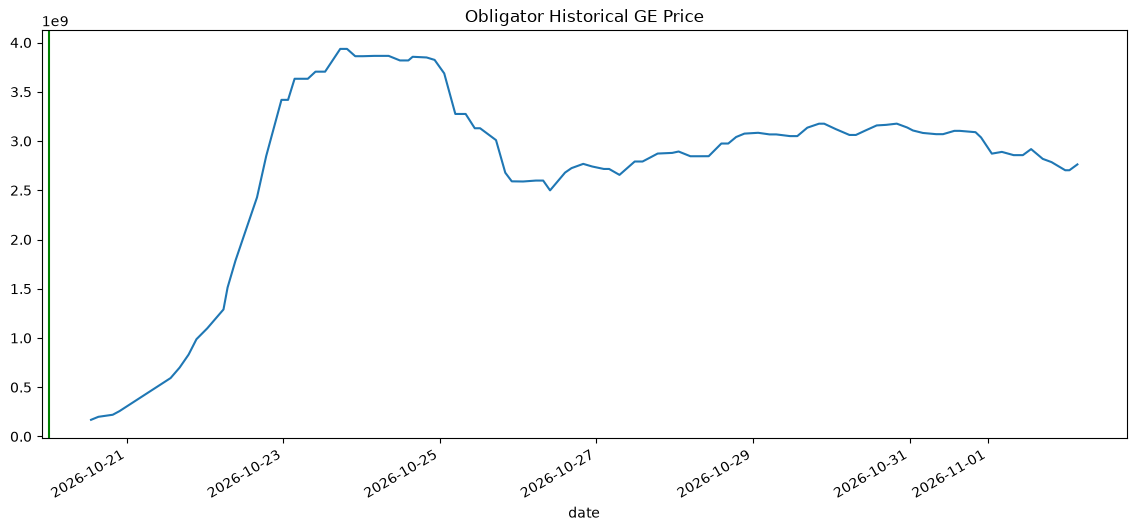

In [10]:
ax = filtered_df.plot(
    x="date",
    y="price",
    figsize=(14, 6),
    title="Obligator Historical GE Price",
    legend=False
)
ax.yaxis.set_major_locator(MultipleLocator(500_000_000))
ax.axvline(pd.to_datetime("2026-10-20"), color="g", zorder=-1)